# Exercise 3: Stability of a Colloidal Dispersion under Reaction Limited Cluster Aggregation (RLCA)
### Julian Barth

## 0) Libraries and constants

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from scipy.optimize import curve_fit
import scipy.integrate as integrate
%config InlineBackend.figure_format = 'retina'

# Parameters (SI Units) 
T = 298.15                 # Temperature [K]
eta = 0.89e-3              # Viscosity [Pa*s]
N0 = 1.4e17                # Initial particle conc. [m^-3]
A_H = 1.5e-20              # Hamaker constant [J]
eps_0 = 8.85e-12           # Vacuum permittivity [F/m]
eps_r = 80.1               # Relative permittivity of water
a = 100e-9                 # Particle radius [m]
psi_0 = 25e-3              # Surface potential [V]
k_B = 1.380649e-23         # Boltzmann constant [J/K]
d_f = 2.1                  # Fractal dimension

# Salt concentration (7.5 mM NaCl)
# Convert to ions/m^3 for the Debye length calculation
c_salt = 7.5  # mol/m^3 (since 1 mM = 1 mol/m^3)
N_A = 6.022e23
e = 1.602e-19
I_ionic = c_salt * N_A     # Ionic strength [ions/m^3]
kappa = np.sqrt((2 * I_ionic * e**2) / (eps_0 * eps_r * k_B * T))

## a)
Since the particles form fractal aggregates ($d_f = 2.1$) rather than coalescing into solid spheres ($d_f = 3$), we use the specific fractal aggregation kernel (Eq 4.19).

$$\beta_{ij}^{DLCA} = \frac{2kT}{3\eta} \left(i^{1/d_f} + j^{1/d_f}\right)\left(i^{-1/d_f} + j^{-1/d_f}\right)$$

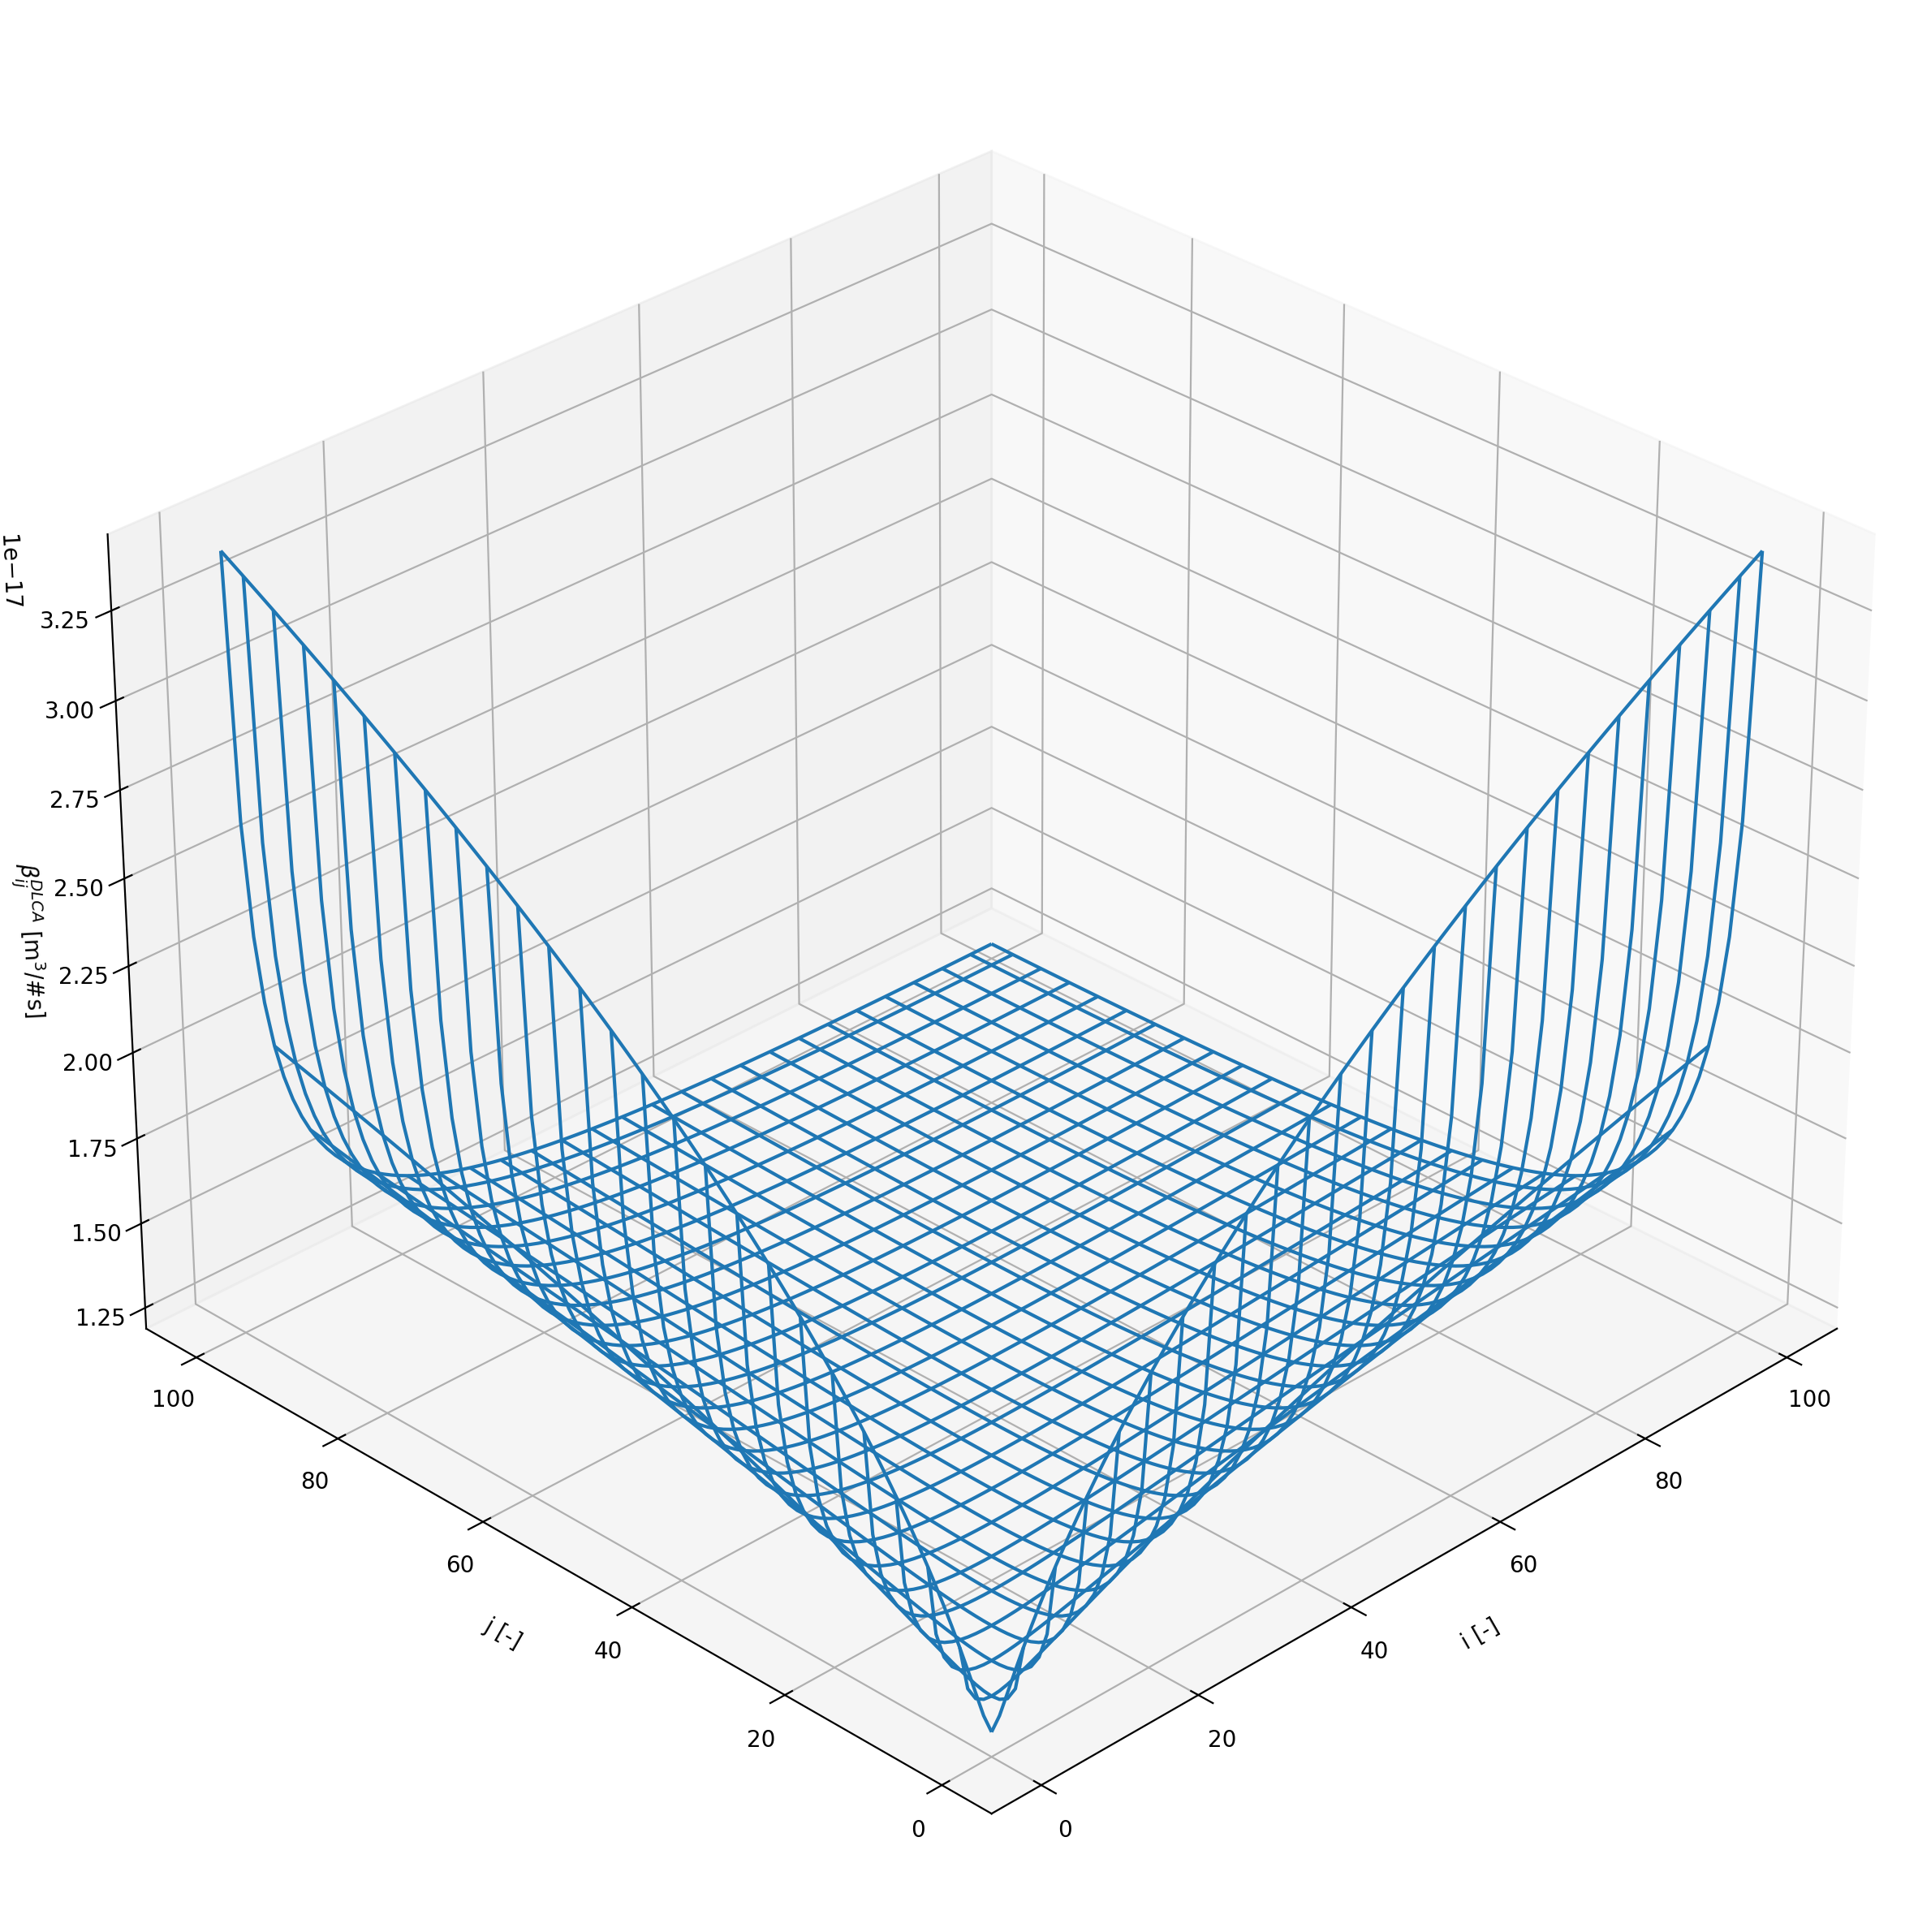

In [3]:
# Create a 100x100 grid for sizes i and j
sizes = np.arange(1, 101)
i_grid, j_grid = np.meshgrid(sizes, sizes)

# DLCA Aggregation Kernel (Eq 4.19)
prefactor = (2 * k_B * T) / (3 * eta)
beta_dlca = prefactor * (i_grid**(1/d_f) + j_grid**(1/d_f)) * (i_grid**(-1/d_f) + j_grid**(-1/d_f))

# Plotting 
fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(111, projection='3d')
ax.plot_wireframe(i_grid, j_grid, beta_dlca, color='tab:blue', rstride=4, cstride=4)
ax.set_xlabel('i [-]')
ax.set_ylabel('j [-]')
ax.set_zlabel(r'$\beta_{ij}^{DLCA}$ [m$^3$/#s]')

# ADDED: view_init to rotate the (0,0) origin to the front center
ax.view_init(elev=30, azim=-135)

plt.tight_layout()
plt.show()

The resulting 3D plot exhibits a U-shape. This shape indicates that collisions between clusters of vastly different sizes (e.g., a highly mobile small cluster and a large cluster with a massive capture radius) occur much faster than collisions between two clusters of the same size.

## b)
Cluster formation is modeled using the Smoluchowski population balance equation (Equation 4.8):
$$\frac{dN_k}{dt} = \frac{1}{2}\sum_{i=1}^{k-1}\beta_{i,k-i}N_i N_{k-i} - N_k\sum_{i=1}^{\infty}\beta_{ik}N_i$$
We integrate this system of ODEs up to a dimensionless mass of $i=100$.

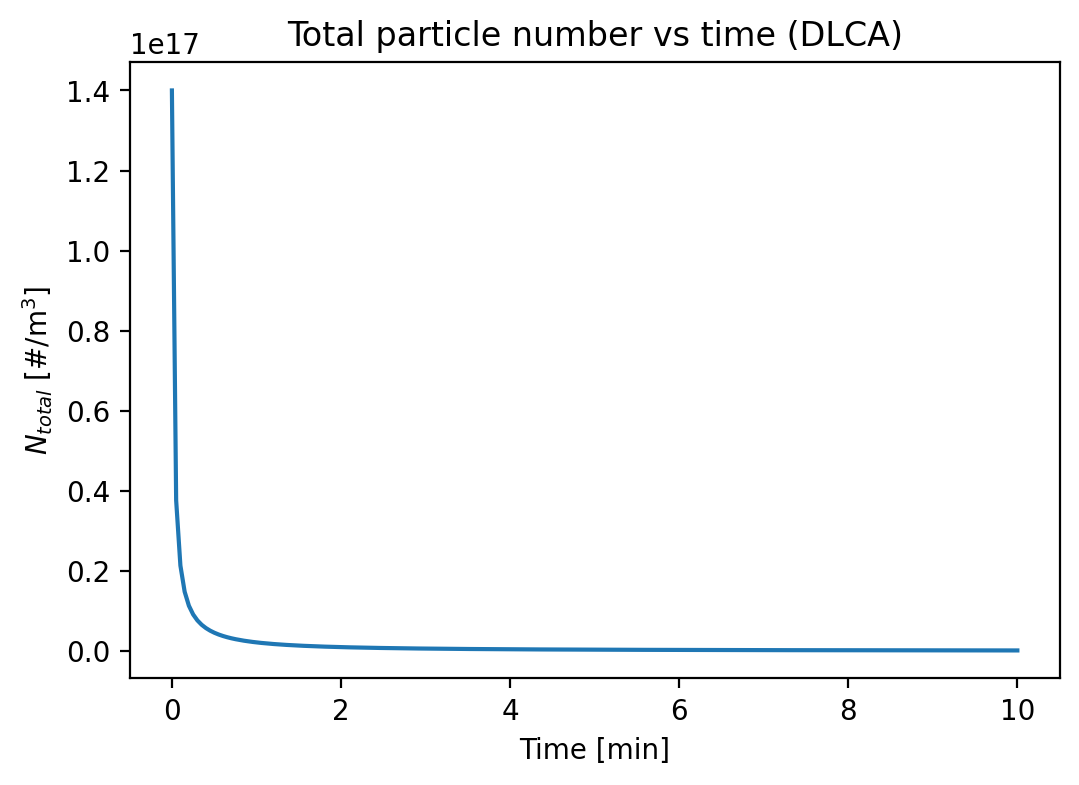

In [4]:
def smoluchowski_ode(N, t, beta_matrix):
    """
    Computes the derivative dN/dt for the Smoluchowski coagulation equation.
    Vectorized to speed up the solver.
    """
    dNdt = np.zeros(len(N))
    
    # Calculate the depletion term for all k simultaneously
    # Depletion: N_k * sum_i(beta_{ki} * N_i)
    depletion = N * np.dot(beta_matrix, N)
    
    for k in range(1, len(N) + 1):
        # Formation term: 1/2 * sum_{i=1}^{k-1} beta_{i, k-i} N_i N_{k-i}
        if k > 1:
            # Indices for i from 1 to k-1 (0-indexed: 0 to k-2)
            i_idx = np.arange(0, k - 1)
            j_idx = k - 2 - i_idx
            
            # Extract the relevant beta values and compute the sum
            beta_sub = beta_matrix[i_idx, j_idx]
            formation = 0.5 * np.sum(beta_sub * N[i_idx] * N[j_idx])
        else:
            formation = 0.0
            
        dNdt[k-1] = formation - depletion[k-1]
        
    return dNdt

# Initial conditions: all mass is in monomers (k=1)
N_init = np.zeros(100)
N_init[0] = N0

# Time array: simulate for 10 minutes (600 seconds)
t_dlca = np.linspace(0, 600, 200)

# Solve the ODEs
N_sol_dlca = odeint(smoluchowski_ode, N_init, t_dlca, args=(beta_dlca,))
N_total_dlca = np.sum(N_sol_dlca, axis=1)

# Plot N_tot vs time
plt.figure(figsize=(6, 4))
plt.plot(t_dlca / 60, N_total_dlca) # Convert seconds to minutes for plot
plt.xlabel('Time [min]')
plt.ylabel(r'$N_{total}$ [#/m$^3$]')
plt.title('Total particle number vs time (DLCA)')
plt.show()

In DLCA, there is no repulsive energy barrier to slow things down. Every collision sticks immediately. Because of this, the primary particles deplete incredibly fast, leading to the rapid, precipitous drop in total particle concentration shown in the plot.

## c)
Unlike DLCA, RLCA features a repulsive barrier that slows down the aggregation process. The rate constant is modified by the Fuchs stability ratio $W$ and an exponent $\lambda$ accounting for the fractal morphology (Equation 4.31):

$$\beta_{ij}^{RLCA} = \frac{\beta_{ij}^{DLCA}}{W} (ij)^\lambda \quad \text{where} \quad \lambda = \frac{d_f - 1}{d_f}$$

Fitted Fuchs Stability Ratio (W): 4.73e+04
R-squared: 0.9974


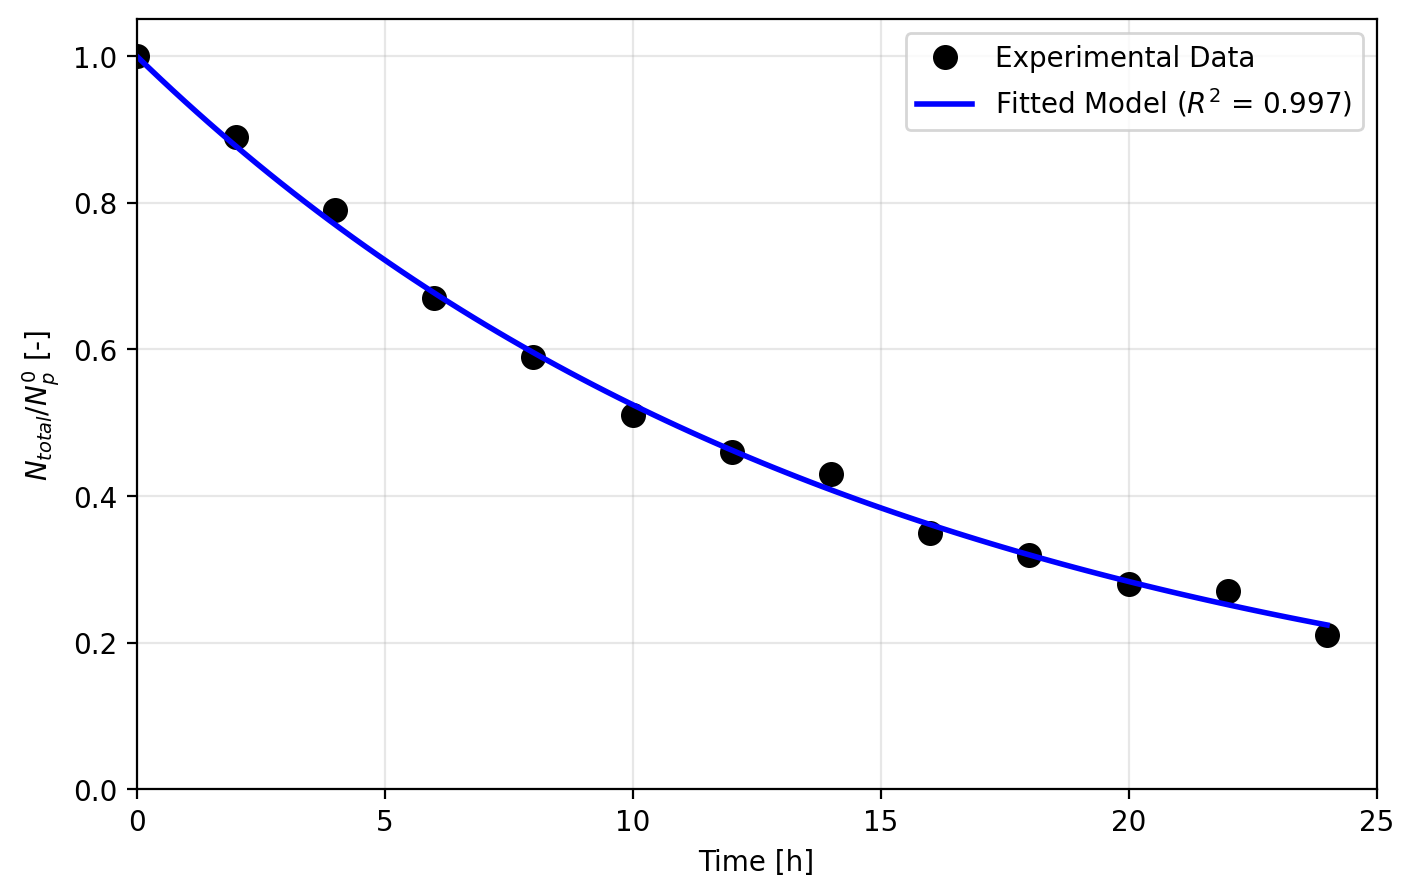

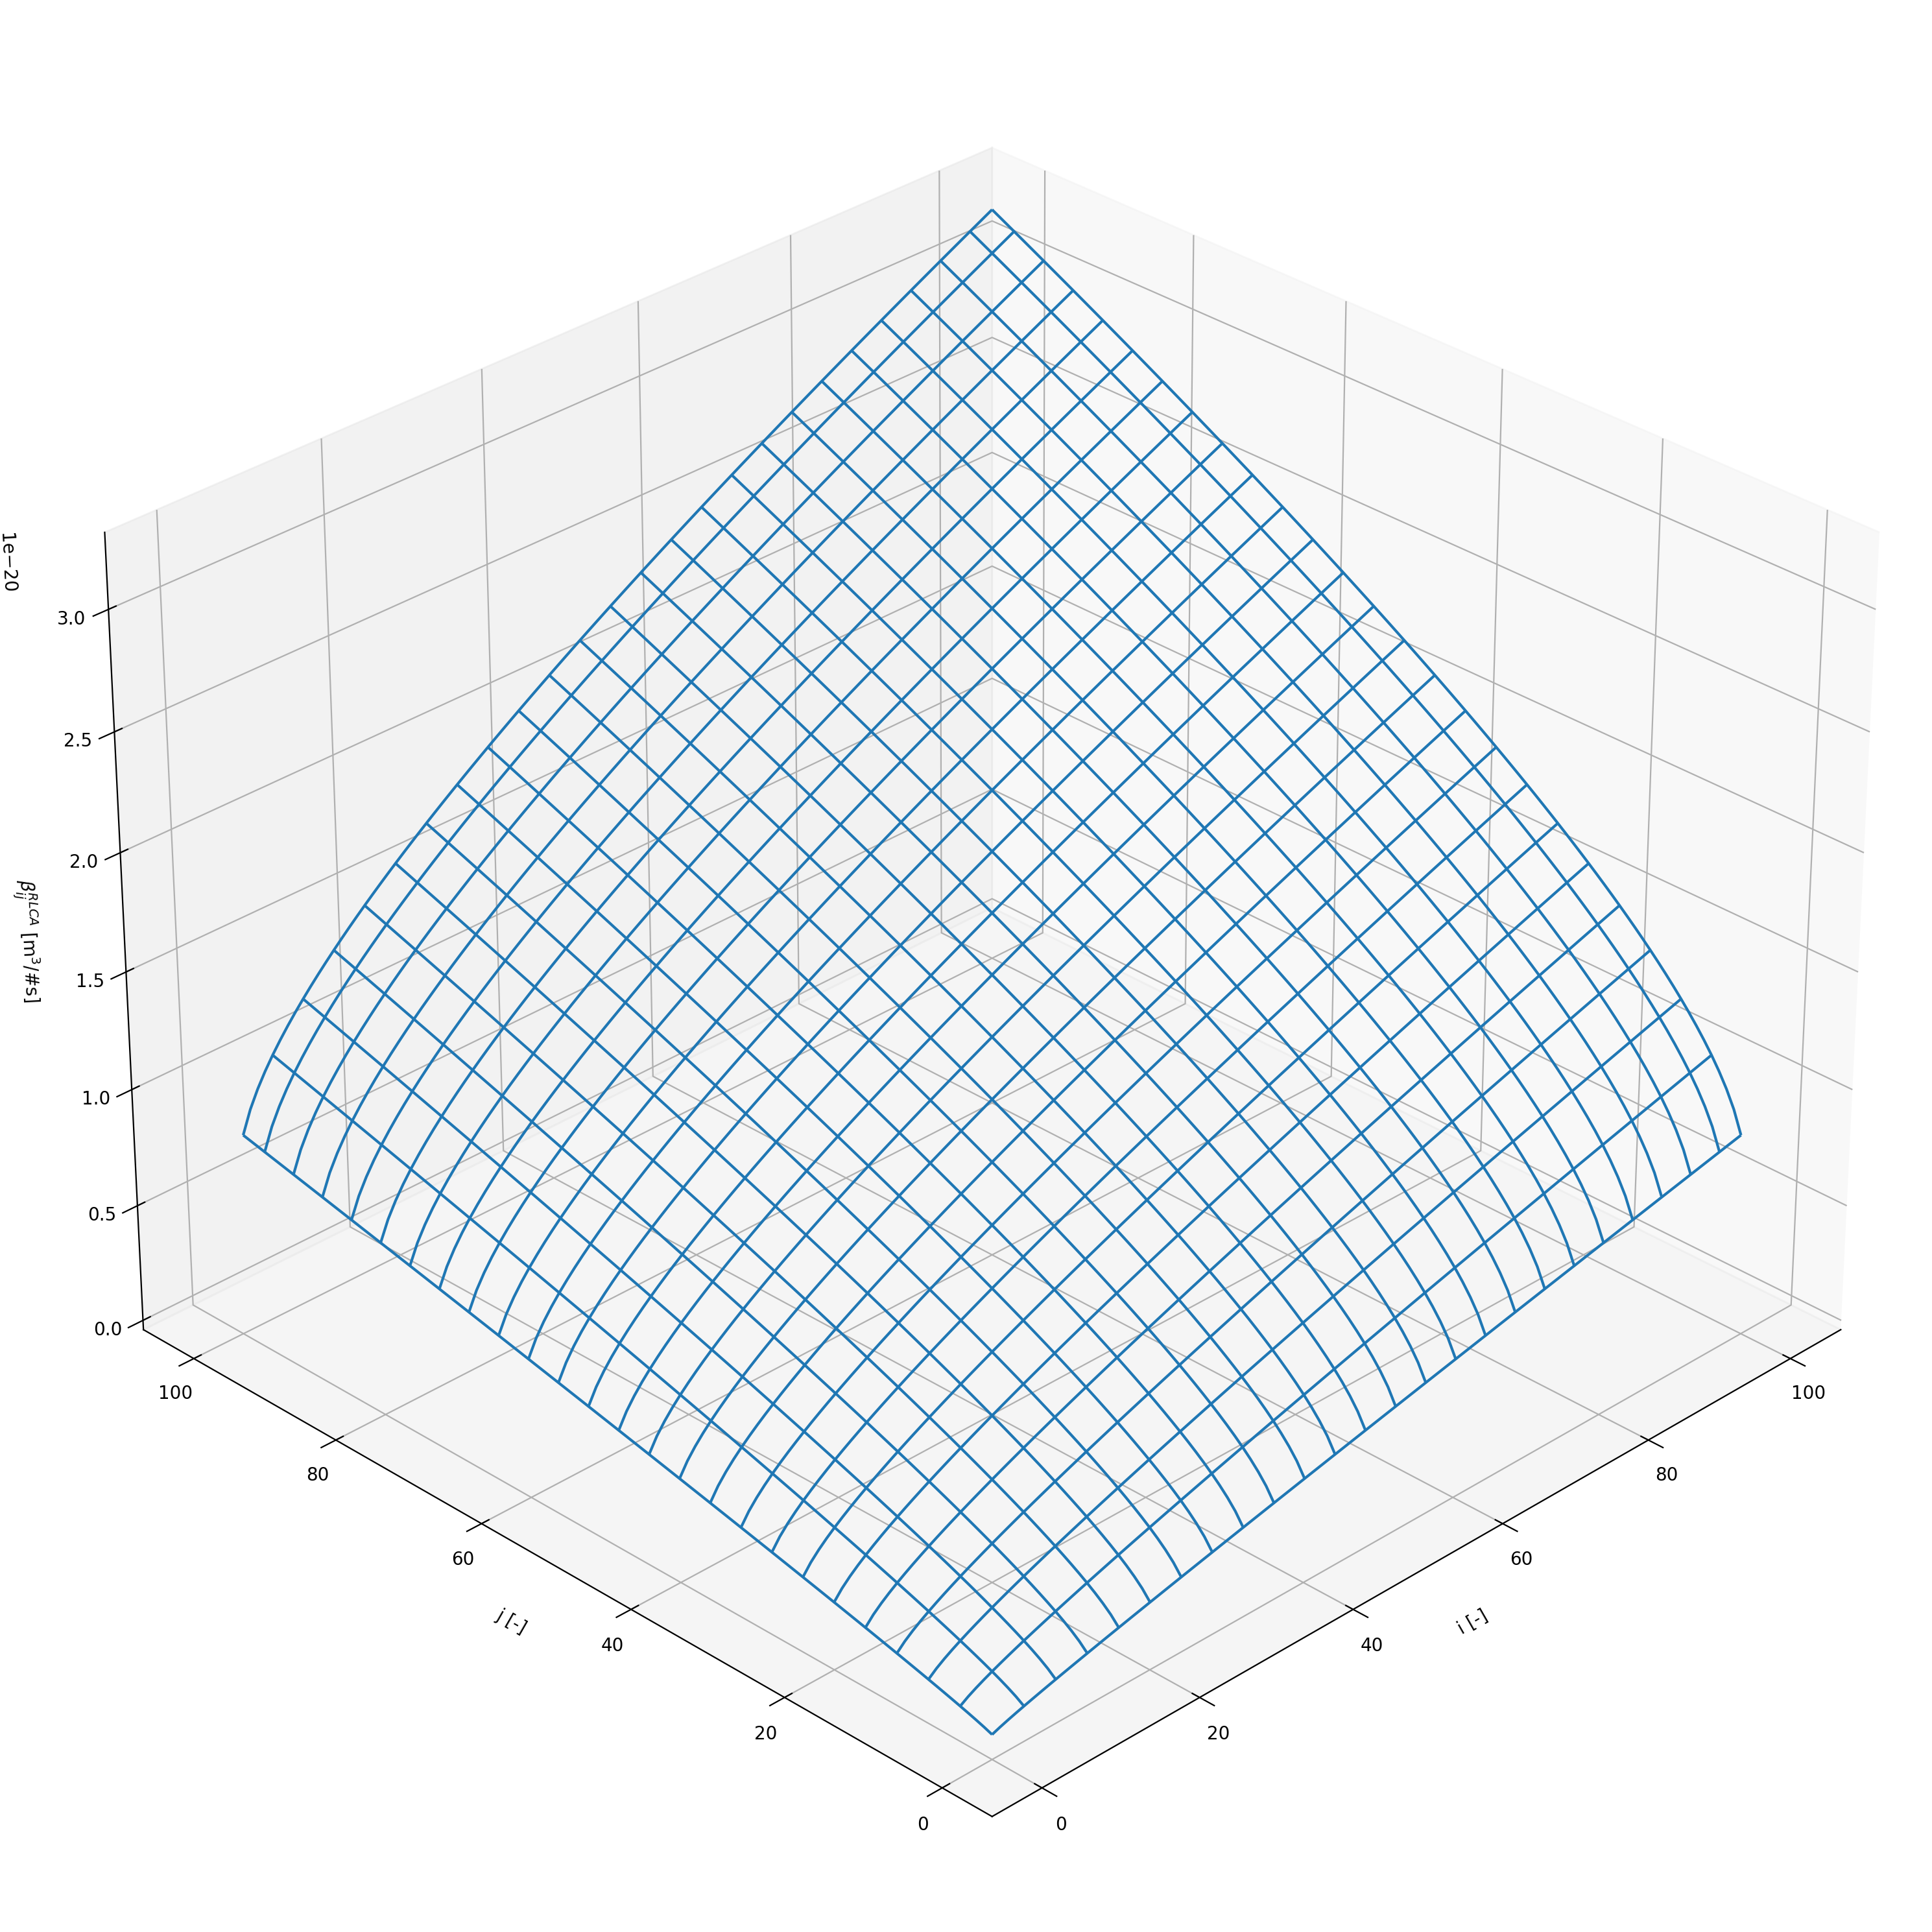

In [8]:
# Calculate lambda for the RLCA kernel adjustment
lam = (d_f - 1) / d_f

# Experimental data provided
t_exp_h = np.array([0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24])
t_exp_s = t_exp_h * 3600  # Convert to seconds
N_ratio_exp = np.array([1.0, 0.89, 0.79, 0.67, 0.59, 0.51, 0.46, 0.43, 0.35, 0.32, 0.28, 0.27, 0.21])

def simulate_rlca_ratio(t_points, W_guess):
    """ Runs the ODE for a given W and returns the normalized total concentration """
    beta_rlca = (beta_dlca / W_guess) * (i_grid * j_grid)**lam
    N_sol = odeint(smoluchowski_ode, N_init, t_points, args=(beta_rlca,))
    return np.sum(N_sol, axis=1) / N0

# We know the guess is around 0.5 * 10^5 from previous batches
# Run curve_fit (this may take a few moments to evaluate the ODEs repeatedly)
popt, pcov = curve_fit(simulate_rlca_ratio, t_exp_s, N_ratio_exp, p0=[50000.0])
W_fitted = popt[0]
print(f"Fitted Fuchs Stability Ratio (W): {W_fitted:.2e}")

# R^2 calculation
N_ratio_pred = simulate_rlca_ratio(t_exp_s, W_fitted)
ss_res = np.sum((N_ratio_exp - N_ratio_pred) ** 2)
ss_tot = np.sum((N_ratio_exp - np.mean(N_ratio_exp)) ** 2)
r_squared = 1 - (ss_res / ss_tot)
print(f"R-squared: {r_squared:.4f}")

# Generate smooth line for the fitted model
t_smooth = np.linspace(0, 24 * 3600, 100)
N_ratio_fit = simulate_rlca_ratio(t_smooth, W_fitted)

# Plot fit vs experimental
plt.figure(figsize=(8, 5))
plt.plot(t_exp_h, N_ratio_exp, 'ko', markersize=8, label='Experimental Data')
plt.plot(t_smooth / 3600, N_ratio_fit, 'b-', linewidth=2, label=f'Fitted Model ($R^2$ = {r_squared:.3f})')
plt.xlabel('Time [h]')
plt.ylabel(r'$N_{total}/N_p^0$ [-]')
plt.legend()
plt.grid(alpha=0.3)
plt.xlim([0, 25])
plt.ylim([0, 1.05])
plt.show()

# Calculate and plot the new RLCA beta surface
beta_rlca_final = (beta_dlca / W_fitted) * (i_grid * j_grid)**lam

fig = plt.figure(figsize=(15, 15))
ax = fig.add_subplot(111, projection='3d')
ax.plot_wireframe(i_grid, j_grid, beta_rlca_final, color='tab:blue', rstride=4, cstride=4)
ax.set_xlabel('i [-]')
ax.set_ylabel('j [-]')
ax.set_zlabel(r'$\beta_{ij}^{RLCA}$ [m$^3$/#s]', labelpad=10)
ax.view_init(elev=30, azim=-135)

plt.tight_layout()
plt.show()

Because aggregates in RLCA have time to probe many configurations before sticking, large-large aggregate collisions are significantly favored relative to the DLCA case. By integrating the ODEs with this new kernel and leaving $W$ as a free parameter, we can minimize the residuals against the experimental timepoints to find the empirical stability ratio. We get an R$^2$ of 0.9974 which shows the model fits the data well 

d)

We compute the theoretical Fuchs stability ratio $W$ by integrating the total DLVO interaction potential $V_T = V_A + V_R$ (Equation 4.26):

$$W = 2a \int_{2a}^{\infty} \exp\left(\frac{V_T}{kT}\right) \frac{dr}{r^2}$$

The attractive and repulsive potentials are defined as follows (with $l = r/a$):

$$V_A = -\frac{A_H}{6} \left[ \frac{2}{l^2 - 4} + \frac{2}{l^2} + \ln\left(1 - \frac{4}{l^2}\right) \right]$$
$$V_R = \frac{4\pi\epsilon_0\epsilon_r a \psi_0^2}{l} \ln\left[1 + \exp(-\kappa a(l-2))\right]$$

In [9]:
# DLVO Potentials as a function of l (where l = r/a)
def V_A(l):
    return -(A_H / 6) * (2/(l**2 - 4) + 2/l**2 + np.log(1 - 4/l**2))

def V_R(l):
    return 4 * np.pi * eps_0 * eps_r * a * psi_0**2 * (1/l) * np.log(1 + np.exp(-kappa * a * (l - 2)))

def V_T(l):
    return V_A(l) + V_R(l)

def W_integrand(l):
    return np.exp(V_T(l) / (k_B * T)) / l**2

# Integrate from l = 2 (contact) to infinity
# To avoid numerical singularity right at l=2, we integrate from 2.0001
integral_result, error = integrate.quad(W_integrand, 2.0001, np.inf)

W_theoretical = 2 * integral_result
print(f"Theoretical W from DLVO: {W_theoretical:.2e}")
print(f"Fitted empirical W: {W_fitted:.2e}")

Theoretical W from DLVO: 1.52e+05
Fitted empirical W: 4.73e+04


The theoretical Fuchs stability ratio calculated from the DLVO potential ($W = 1.52 \times 10^5$) is roughly three times larger than the empirical fit ($W = 4.73 \times 10^4$). The theoretical result helps get a result of good order of magnitude, but lacks precision. 

This is because the stability ratio $W$ depends exponentially on the maximum energy barrier $V_{T,max}$. Due to this  sensitivity, even a minor 7% change in the surface potential $\psi_0$ can result in a ten-fold variation in $W$.   

The fact that the theoretical model slightly overestimates the stability (predicting a slower aggregation rate than what is observed experimentally) stems from its idealized assumptions. The theoretical calculation assumes perfectly smooth, spherical particles with a constant surface potential ($\psi_0 = 25$ mV) and a uniform charge distribution. In reality, surface roughness, localized charge patches, or dynamic charge regulation during collisions can lower the effective repulsive barrier, increasing the successful collision rate beyond the DLVO prediction.   

e)

Using the fitted $W$, we plot the distribution of clusters at 1h, 4h, and 8h. As the primary particles are depleted, the distribution flattens and shifts outward as larger fractal aggregates dominate.

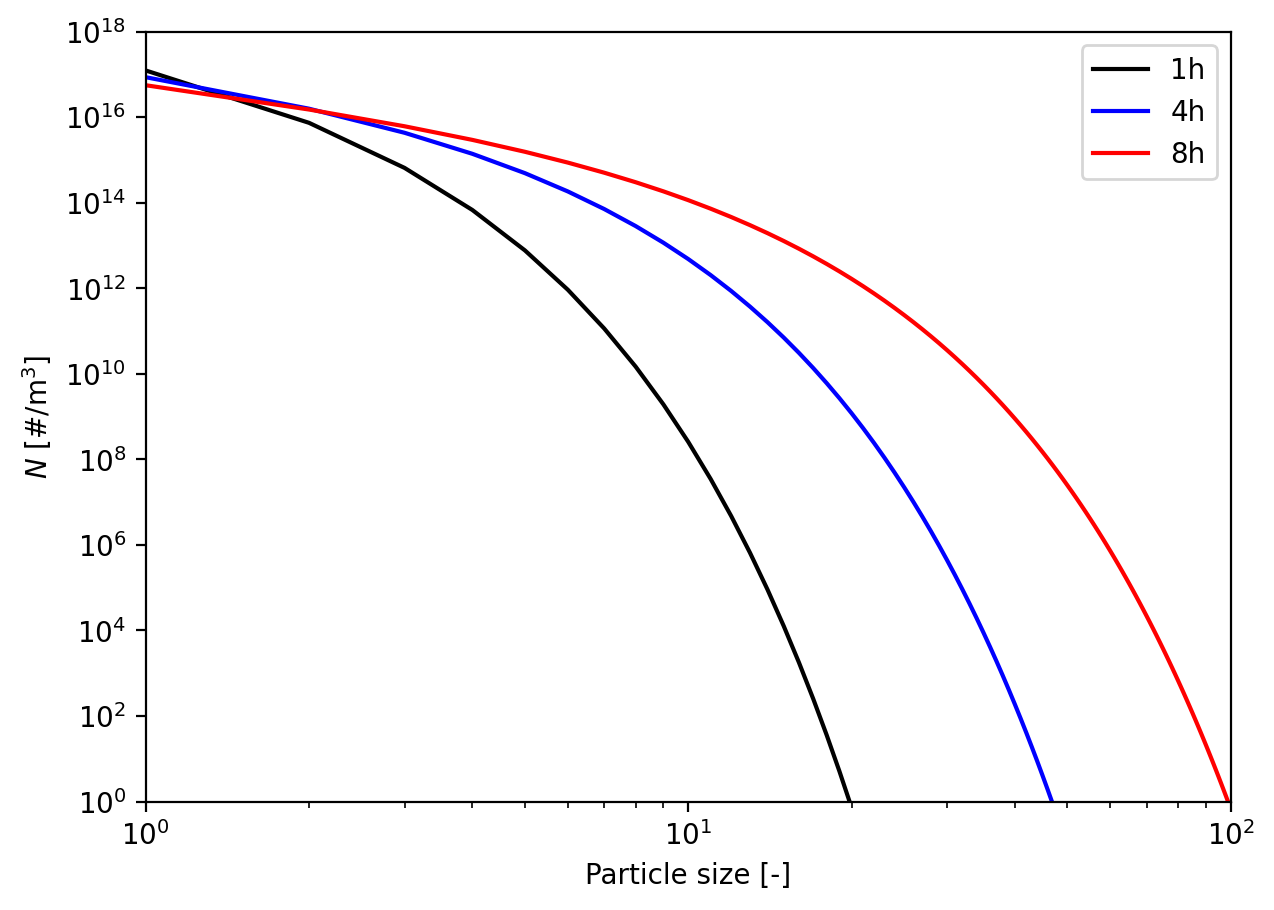

In [10]:
# Evaluate ODE at specific times using the fitted RLCA beta
t_eval_h = np.array([1, 4, 8])
t_eval_s = t_eval_h * 3600

N_sol_eval = odeint(smoluchowski_ode, N_init, np.concatenate(([0], t_eval_s)), args=(beta_rlca_final,))

# Extract the distributions (indices 1, 2, 3 correspond to 1h, 4h, 8h)
N_1h = N_sol_eval[1, :]
N_4h = N_sol_eval[2, :]
N_8h = N_sol_eval[3, :]

plt.figure(figsize=(7, 5))
plt.loglog(sizes, N_1h, 'k-', label='1h')
plt.loglog(sizes, N_4h, 'b-', label='4h')
plt.loglog(sizes, N_8h, 'r-', label='8h')

plt.xlabel('Particle size [-]')
plt.ylabel(r'$N$ [#/m$^3$]')
plt.legend()
plt.xlim([1, 100])
plt.ylim([1e0, 1e18]) # Adjust y-limits to match typical log profiles
plt.show()

The simulated distributions at 1h, 4h, and 8h illustrate the progressive flattening and broadening of the cluster mass distribution as primary particles aggregate into larger fractal structures. In Reaction Limited Cluster Aggregation (RLCA), the distribution does not develop the characteristic bell-shape seen in diffusion-limited regimes. Instead, because the RLCA aggregation kernel strongly favors collisions between already large clusters, the distribution remains exceptionally broad and primary particles persist in the system even at large aggregation times.   

The primary limitation of this specific numerical approach is the artificial truncation of the aggregate mass at 
$𝑖=100$. Given that the RLCA mechanism inherently accelerates large-large cluster interactions, a significant fraction of the system's mass rapidly attempts to form clusters exceeding this upper boundary. By capping the population balance equations at a dimensionless mass of 100, the model acts as an artificial sink for larger aggregates, eventually violating mass conservation and losing predictive accuracy for longer time scales. To accurately predict late-stage coagulation, the model requires either a vastly expanded mass array or the implementation of a statistical scaling solution.   